## Predictive Modeling (Classification)
**Dataset:** Customer churn data (churn-bigml-80 for training, churn-bigml-20 for testing)
**Goal:** Predict if a customer will leave the company, compare three models, and improve the best one with grid search.
**Tools:** Python, scikit-learn, pandas, matplotlib

##  Load the data
I load the training file and the testing file.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, ConfusionMatrixDisplay)

os.makedirs("plots", exist_ok=True)

train = pd.read_csv("../datasets/churn-bigml-80.csv")
test = pd.read_csv("../datasets/churn-bigml-20.csv")

print("Training rows and columns:", train.shape)
print("Testing rows and columns:", test.shape)
train.head()

Training rows and columns: (2666, 20)
Testing rows and columns: (667, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


## Look at the data
I tidy the column names, check for missing values, and look at how many customers left.

In [2]:
train.columns = train.columns.str.strip().str.lower().str.replace(" ", "_")
test.columns = test.columns.str.strip().str.lower().str.replace(" ", "_")

train.info()
print("Missing values:", train.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   2666 non-null   str    
 1   account_length          2666 non-null   int64  
 2   area_code               2666 non-null   int64  
 3   international_plan      2666 non-null   str    
 4   voice_mail_plan         2666 non-null   str    
 5   number_vmail_messages   2666 non-null   int64  
 6   total_day_minutes       2666 non-null   float64
 7   total_day_calls         2666 non-null   int64  
 8   total_day_charge        2666 non-null   float64
 9   total_eve_minutes       2666 non-null   float64
 10  total_eve_calls         2666 non-null   int64  
 11  total_eve_charge        2666 non-null   float64
 12  total_night_minutes     2666 non-null   float64
 13  total_night_calls       2666 non-null   int64  
 14  total_night_charge      2666 non-null   float64
 15

## Preprocess the data, part 1
Models work with numbers, so I change Yes/No and True/False columns into 1 and 0.

In [3]:
def to_number(column):
    words = column.astype(str).str.strip().str.lower()
    return words.map({"yes": 1, "no": 0, "true": 1, "false": 0,
                      "1": 1, "0": 0, "1.0": 1, "0.0": 0})

for col in ["international_plan", "voice_mail_plan", "churn"]:
    train[col] = to_number(train[col])
    test[col] = to_number(test[col])

print(train[["international_plan", "voice_mail_plan", "churn"]].isnull().sum())

international_plan    0
voice_mail_plan       0
churn                 0
dtype: int64


## Check the balance of the data
I count how many customers stayed and how many left.

In [4]:
print(train["churn"].value_counts())
print(train["churn"].value_counts(normalize=True).round(2))

churn
0    2278
1     388
Name: count, dtype: int64
churn
0    0.85
1    0.15
Name: proportion, dtype: float64


Only about 15% of the customers left, and 85% stayed. This means the data is unbalanced, so accuracy alone can be misleading. I will also look at precision, recall and F1-score.

## Preprocess the data, part 2
The state and area code columns are categories, not amounts. I turn each category into its own 0/1 column (one-hot encoding).

In [5]:
train["part"] = "train"
test["part"] = "test"
both = pd.concat([train, test])

both = pd.get_dummies(both, columns=["state", "area_code"], dtype=int)

train = both[both["part"] == "train"].drop(columns="part")
test = both[both["part"] == "test"].drop(columns="part")

print("Training:", train.shape)
print("Testing:", test.shape)

Training: (2666, 72)
Testing: (667, 72)


## Choose X and y
X is what the model looks at. y is what it must predict (did the customer leave).

In [6]:
X_train = train.drop(columns="churn")
y_train = train["churn"]

X_test = test.drop(columns="churn")
y_test = test["churn"]

## Preprocess the data, part 3
Columns like total minutes and account length have different sizes. I scale them so they are all on the same level. I learn the scale from the training data only.

In [7]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]
print(len(num_cols), "number columns will be scaled")

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

15 number columns will be scaled


## Train and test the models
I train three models on the training data, then test each one on customers it has never seen.
- Logistic Regression: draws a smooth line between "stays" and "leaves"
- Decision Tree: asks a series of yes/no questions, like a flow chart
- Random Forest: many decision trees that vote together

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.855,0.477,0.221,0.302
1,Decision Tree,0.930,0.755,0.747,0.751
2,Random Forest,0.940,0.982,0.589,0.737


 Model 1 had the highest F1-score of 0.751, Logistic Regression had an accuracy of 0.855 but a low recall of 0.221, so it missed many customers who left. The Random Forest caught 58.9% of the customers who left.

## Compare the models in a chart
I draw the scores of the three models side by side.

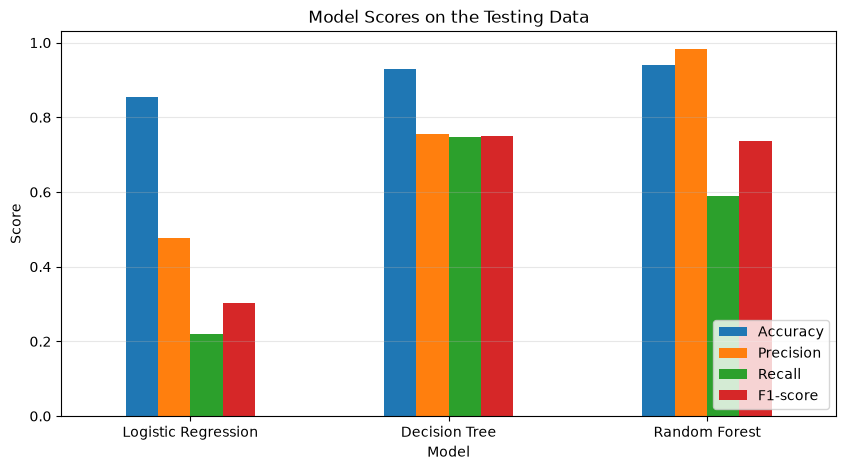

In [9]:
results.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Model Scores on the Testing Data")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.savefig("plots/model_comparison.png")
plt.show()

## Hyperparameter tuning with grid search
Models have settings, such as how many trees to use. Grid search tries many combinations of settings and picks the best one. I tune the Random Forest and score it by F1.

In [10]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 3],
    "class_weight": [None, "balanced"],
}

grid = GridSearchCV(RandomForestClassifier(random_state=42),
                    param_grid, scoring="f1", cv=5)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best F1 score:", round(grid.best_score_, 3))

Best settings: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best F1 score: 0.788


## Test the tuned model
I test the best Random Forest on the testing data and compare it with the other models.

In [11]:
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

tuned = pd.DataFrame([{
    "Model": "Random Forest (tuned)",
    "Accuracy": accuracy_score(y_test, best_pred),
    "Precision": precision_score(y_test, best_pred),
    "Recall": recall_score(y_test, best_pred),
    "F1-score": f1_score(y_test, best_pred),
}]).round(3)

final_results = pd.concat([results, tuned], ignore_index=True)
final_results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.855,0.477,0.221,0.302
1,Decision Tree,0.930,0.755,0.747,0.751
2,Random Forest,0.940,0.982,0.589,0.737
3,Random Forest (tuned),0.955,0.874,0.800,0.835


Grid search chose these settings, Best settings: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best F1 score: 0.788. The tuned Random Forest had an F1-score of 0.835, compared with 0.737 before tuning. Tuning slightly improved the result.

## Confusion matrix
A confusion matrix shows where the model was right and wrong.

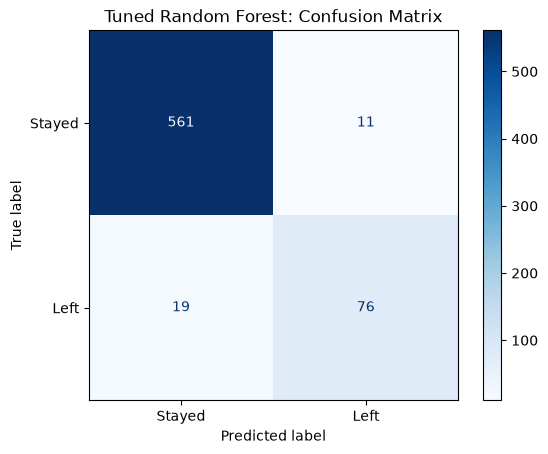

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, best_pred,
                                        display_labels=["Stayed", "Left"],
                                        cmap="Blues")
plt.title("Tuned Random Forest: Confusion Matrix")

plt.savefig("plots/confusion_matrix.png")
plt.show()

## Which features matter most?
The Random Forest can tell me which columns helped it most to make its guesses.

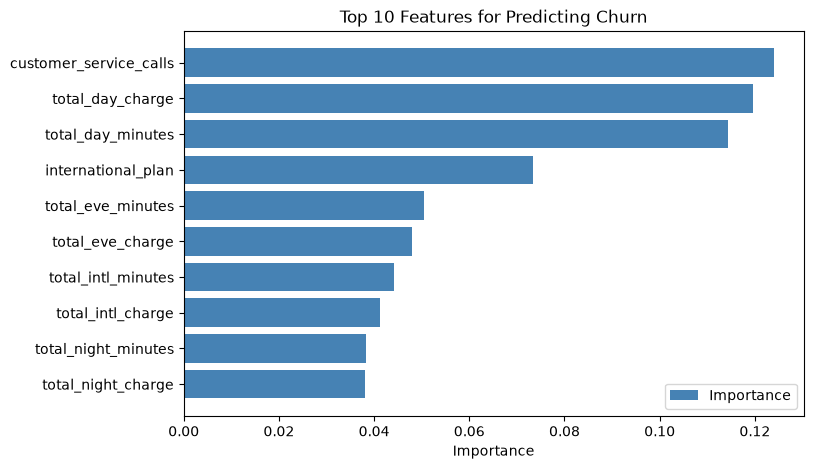

In [13]:
importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
top = importance.sort_values().tail(10)

plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="steelblue", label="Importance")
plt.title("Top 10 Features for Predicting Churn")
plt.xlabel("Importance")
plt.legend()

plt.savefig("plots/feature_importance.png")
plt.show()

The most important features were customer_service_calls,total_day_charge and total_day_minutes. This suggests that customers who call customer service many times are more likely to leave, and also those with total day charge and total day minutes based on the model.

## Summary
I analysed customer churn. There are 2666 customers in my training data and 667 in the test data.
Only around 14.6% of those in the training data have churned. However, because the data is imbalanced, results should not just be analysed using accuracy. Precision, recall and F1-score were also investigated.
I converted ‘Yes’ and ‘No’ data into 1s and 0s. State and area code were then converted into 0s and 1s. Numerical data was also normalised.
A Logistic Regression, Decision Tree and Random Forest model were all created.
Logistic Regression achieved reasonable accuracy (0.855) but performed less well than the other models. It only had a recall value of 0.221; so it only identified around 22 in every 100 customers who churned. Its F1-score was 0.302.
The Decision Tree performed far better and had a good F1-score of 0.751. This model had a good balance between its precision (0.755) and recall (0.747).
While the Random Forest had excellent precision (0.982), meaning that it was highly likely to correctly identify a customer who is going to churn, it only had a recall of 0.589. Therefore, it failed to detect around 4 in 10 customers who actually churned. This model had a F1-score of 0.737.
Using grid search the following hyperparameters were set for the Random Forest: 200 trees, unlimited tree depth, a minimum leaf node size of 1 and equal weighting of the classes.
After tuning the Random Forest became my best model. Its F1-score was improved to 0.835. Recall was also greatly increased to 0.800. Precision was still good (0.874). Accuracy was 0.955.
Of the 95 customers who actually churned, the tuned model correctly recognised 76. It failed to recognise 19. Of the 572 customers who did not churn, only 11 were incorrectly recognised as having churned.
While tuning the model it began to focus more on identifying customers who churn. Consequently it is now much better at doing so. However, there is a slight reduction in precision (from 0.982 to 0.874).
The key variables were number of customer services calls, daily charge and daily minutes.
All graphs were exported as image files and saved in a ‘plots’ folder.